### Energy Generation Data

In [369]:
import pandas as pd

In [370]:
energy_gen = 'energy generation_daily.xlsx'  # Replace with your actual file path
data = pd.read_excel(energy_gen, sheet_name=0)

In [371]:
print(pd.read_excel('energy generation_daily.xlsx').columns)

Index(['Datum von', 'Datum bis', 'Biomasse [MWh]', 'Wasserkraft [MWh]',
       'Wind Offshore [MWh]', 'Wind Onshore [MWh]', 'Photovoltaik [MWh]',
       'Sonstige Erneuerbare [MWh]', 'Kernenergie [MWh]', 'Braunkohle [MWh]',
       'Steinkohle [MWh]', 'Erdgas [MWh]', 'Pumpspeicher [MWh]',
       'Sonstige Konventionelle [MWh]'],
      dtype='object')


In [372]:
# Rename German column names to English
column_rename_map = {
    'Datum von': 'date',
    'Datum bis': 'End Date',
    'Braunkohle [MWh]': 'Lignite',
    'Steinkohle [MWh]': 'Hard Coal',
    'Wind Offshore [MWh]': 'Wind Offshore',
    'Wind Onshore [MWh]': 'Wind Onshore',
    'Biomasse [MWh]': 'biomass',
    'Wasserkraft [MWh]': 'hydropower',
    'Photovoltaik [MWh]': 'solar',
    'Sonstige Erneuerbare [MWh]': 'other renewables',
    'Kernenergie [MWh]': 'nuclear',
    'Erdgas [MWh]': 'natural gas',
    'Pumpspeicher [MWh]': 'pumped storage',
    'Sonstige Konventionelle [MWh]': 'other conventional'
}

In [373]:
data.rename(columns=column_rename_map, inplace=True)

In [374]:
# Drop the "End Date" column
data.drop(columns=['End Date'], inplace=True)

In [375]:
# Combine "Lignite" and "Hard Coal" into a single "Coal" column
data['coal'] = data['Lignite'] + data['Hard Coal']

In [376]:
# Combine "Wind Offshore" and "Wind Onshore" into a single "Wind" column
data['wind'] = data['Wind Offshore'] + data['Wind Onshore']

In [377]:
data.drop(columns=['Lignite', 'Hard Coal', 'Wind Offshore', 'Wind Onshore'], inplace=True)

In [378]:
output_energy_gen = "output files\energy_generation.csv"
data.to_csv(output_energy_gen, index=False)

In [379]:
print("Data updated successfully!")

Data updated successfully!


### Energy Consumption Data

In [380]:
import pandas as pd

In [381]:
energy_con = 'energy consumption_daily.xlsx'  # Replace with your actual file path
data = pd.read_excel(energy_con)

In [382]:
print(pd.read_excel('energy consumption_daily.xlsx').columns)

Index(['Datum von', 'Datum bis', 'Gesamt (Netzlast) [MWh]',
       'Residuallast [MWh]', 'Pumpspeicher [MWh]'],
      dtype='object')


In [383]:
# Rename German column names to English
column_rename_map = {
    'Datum von': 'date',
    'Datum bis': 'End Date',
    'Gesamt (Netzlast) [MWh]': 'total energy consumption',
    'Residuallast [MWh]': 'Residual Load',
    'Pumpspeicher [MWh]': 'Pumped Storage'
}

In [384]:
data.rename(columns=column_rename_map, inplace=True)

In [385]:
# Drop unnecessary columns ("End Date", "Residual Load", "Pumped Storage")
data.drop(columns=['End Date', 'Residual Load', 'Pumped Storage'], inplace=True)

In [386]:
output_energy_con = "output files\energy_consumption.csv"
data.to_csv(output_energy_con, index=False)

In [387]:
print("Data updated and saved successfully!")

Data updated and saved successfully!


### CO2 Emissions Data

In [388]:
import pandas as pd

In [389]:
# Load the two Excel files
file1 = 'co2_emissions_2019_2021.xlsx'  # Replace with your file path
file2 = 'co2_emissions_2022_2024.xlsx'  # Replace with your file path

In [390]:
# Read both files into DataFrames
data1 = pd.read_excel(file1, sheet_name=0)  # Adjust sheet_name if needed
data2 = pd.read_excel(file2, sheet_name=0)  # Adjust sheet_name if needed

In [391]:
# Combine the two files
data = pd.concat([data1, data2], ignore_index=True)

In [392]:
# Drop the "country" column
if 'country' in data.columns:
    data.drop(columns=['country'], inplace=True)

In [393]:
# Ensure the 'date' column is in datetime format
data['date'] = pd.to_datetime(data['date'], format='%d/%m/%Y', errors='coerce')

In [394]:
# Combine "Domestic Aviation" and "International Aviation" into a single "aviation_co2" value
aviation_sum = data[data['sector'].isin(['Domestic Aviation', 'International Aviation'])] \
    .groupby(['date'], as_index=False)['MtCO2 per day'].sum()
aviation_sum['sector'] = 'aviation_co2'

In [395]:
# Remove the original aviation rows and append the summed "aviation_co2" row
data = data[~data['sector'].isin(['Domestic Aviation', 'International Aviation'])]
data = pd.concat([data, aviation_sum], ignore_index=True)

In [396]:
# Rename sectors for consistency
data['sector'] = data['sector'].replace({
    'Power': 'electricity_co2',
    'Ground Transport': 'transport_co2',
    'Residential': 'residential_co2',
    'Industry': 'industry_co2'
})

In [397]:
# Pivot the sector column into separate columns
data_pivot = data.pivot(index='date', columns='sector', values='MtCO2 per day').reset_index()

In [398]:
# Add missing rows for Nov-Dec 2024
all_dates = pd.date_range(start='2019-01-01', end='2024-12-31', freq='D')
data_pivot = data_pivot.set_index('date')
data_pivot = data_pivot.reindex(all_dates).reset_index()
data_pivot.rename(columns={'index': 'date'}, inplace=True)

In [399]:
# Fill missing rows for Nov-Dec 2024
data_pivot['date'] = data_pivot['date'].dt.strftime('%d.%m.%Y')
missing_2024 = data_pivot[(data_pivot['date'] >= '01.11.2024') & (data_pivot['date'] <= '31.12.2024')]

In [400]:
for index, row in missing_2024.iterrows():
    # Find the corresponding date in 2023
    corresponding_date = row['date'][:-4] + '2023'
    
    # Locate the corresponding row in 2023
    corresponding_row = data_pivot[data_pivot['date'] == corresponding_date]
    
    if not corresponding_row.empty:
        for col in data_pivot.columns.difference(['date']):
            if pd.isnull(data_pivot.loc[index, col]):
                data_pivot.loc[index, col] = corresponding_row.iloc[0][col]

In [401]:
# Recalculate total CO2 emissions
data_pivot['total CO2 emissions'] = data_pivot.drop(columns=['date']).sum(axis=1)

In [402]:
filled_2024 = data_pivot[(data_pivot['date'] >= '01.11.2024') & (data_pivot['date'] <= '31.12.2024')]
print("Filled Values for November-December 2024:")
print(filled_2024)

Filled Values for November-December 2024:
sector        date  aviation_co2  electricity_co2  industry_co2  \
1       02.01.2019      0.062398         0.438037      0.158906   
2       03.01.2019      0.065826         0.619551      0.224754   
3       04.01.2019      0.067999         0.682394      0.247551   
4       05.01.2019      0.069157         0.685610      0.248718   
5       06.01.2019      0.070776         0.718353      0.260596   
...            ...           ...              ...           ...   
2187    27.12.2024      0.064295         0.264254      0.126167   
2188    28.12.2024      0.063491         0.256318      0.122378   
2189    29.12.2024      0.062472         0.253104      0.120844   
2190    30.12.2024      0.061823         0.250502      0.119601   
2191    31.12.2024      0.061410         0.252624      0.120615   

sector  residential_co2  transport_co2  total CO2 emissions  
1              0.624299       0.277497             1.561137  
2              0.676751      

In [403]:
output_file_path = 'output files/co2_emissions.csv'
data_pivot.to_csv(output_file_path, index=False)
print("CO2 emissions data processed and saved successfully!")

CO2 emissions data processed and saved successfully!


### GDP Data

In [404]:
import pandas as pd

In [405]:
# Load energy consumption data
energy_file_path = 'output files\energy_consumption.csv'  # Replace with your actual file path
energy_data = pd.read_csv(energy_file_path)

In [406]:
# Explicitly parse the date column in energy data (format: DD.MM.YYYY)
energy_data['date'] = pd.to_datetime(energy_data['date'], format='%d.%m.%Y')

In [407]:
# Load GDP data
gdp_file_path = 'GDP.csv'  # Replace with your actual file path
gdp_data = pd.read_csv(gdp_file_path)

In [408]:
# Parse GDP data dates in "M/D/YYYY" format
gdp_data['date'] = pd.to_datetime(gdp_data['date'], format='%m/%d/%Y')

In [409]:
# Create a full daily date range from 1st Jan 2019 to 31st Dec 2024
full_date_range = pd.date_range(start='2019-01-01', end='2024-12-31', freq='D')

In [410]:
# Reindex energy data to the full date range, filling missing dates
energy_data = energy_data.set_index('date').reindex(full_date_range).reset_index().rename(columns={'index': 'date'})

In [411]:
# Forward-fill missing energy consumption values if necessary
energy_data['total energy consumption'] = pd.to_numeric(
    energy_data['total energy consumption'], errors='coerce'
)  # Ensure numeric
energy_data['total energy consumption'] = energy_data['total energy consumption'].fillna(method='ffill')

In [412]:
# Interpolate missing GDP values for July 2024 to December 2024 using linear interpolation
# Set 'date' as the index for interpolation
gdp_data = gdp_data.set_index('date').reindex(full_date_range).reset_index().rename(columns={'index': 'date'})

In [413]:
gdp_data['GDP'] = gdp_data['GDP'].interpolate(method='linear')

In [414]:
# Expand GDP data to daily frequency using forward-fill
#gdp_data = gdp_data.set_index('date').resample('D').ffill().reset_index()

In [415]:
# Merge energy and GDP data on the daily date range
merged_data = pd.merge(energy_data, gdp_data, on='date', how='left')

In [416]:
# Ensure 'Total Energy Consumption' is numeric in merged_data
merged_data['total energy consumption'] = pd.to_numeric(
    merged_data['total energy consumption'], errors='coerce'
).fillna(0)

In [417]:
# Calculate quarterly totals of energy consumption
merged_data['Quarter'] = merged_data['date'].dt.to_period('Q')
quarterly_totals = merged_data.groupby('Quarter')['total energy consumption'].transform('sum')

In [418]:
# Calculate daily weights based on energy consumption within each quarter
merged_data['Daily Weight'] = merged_data['total energy consumption'] / quarterly_totals

In [419]:
# Calculate daily GDP using the weights
merged_data['gdp'] = merged_data['GDP'] * merged_data['Daily Weight']

In [420]:
# Ensure the 'date' column is in datetime format before formatting
merged_data['date'] = pd.to_datetime(merged_data['date'], errors='coerce')

In [421]:
# Format the date column to "DD.MM.YYYY"
merged_data['date'] = merged_data['date'].dt.strftime('%d.%m.%Y')

In [422]:
# Select only the 'date' and 'Daily GDP' columns
result_data = merged_data[['date', 'gdp']]

In [423]:
result_file_path = 'output files\gdp.csv'  # Specify your desired output file name
result_data.to_csv(result_file_path, index=False)
print(f"Daily GDP data saved successfully to {result_file_path}!")

Daily GDP data saved successfully to output files\gdp.csv!


### Population Data

In [424]:
import pandas as pd

In [425]:
# Load yearly population data
population_file_path = 'population.xlsx'  # Replace with your actual file path
population_data = pd.read_excel(population_file_path)

In [426]:
# Parse the 'year' column to datetime format (set to January 1 of each year)
population_data['year'] = pd.to_datetime(population_data['year'], format='%Y')

In [427]:
# Print population data to confirm 2025 value is present
print("Input Population Data:")
print(population_data)

Input Population Data:
        year  population
0 2019-01-01       83.09
1 2020-01-01       83.16
2 2021-01-01       83.20
3 2022-01-01       83.80
4 2023-01-01       84.51
5 2024-01-01       84.83
6 2025-01-01       84.98


In [428]:
# Set the year as the index for interpolation
population_data.set_index('year', inplace=True)

In [429]:
# Generate a daily date range from 1st Jan 2019 to 31st Dec 2024
daily_date_range = pd.date_range(start='2019-01-01', end='2024-12-31', freq='D')

In [430]:
# Reindex to daily frequency and interpolate linearly
daily_population_data = population_data.reindex(daily_date_range).interpolate(method='linear').reset_index()

In [431]:
# Rename columns for clarity
daily_population_data.rename(columns={'index': 'date', 'population': 'population'}, inplace=True)

In [432]:
# Filter the result to the target range (2019-01-01 to 2024-12-31)
daily_population_data = daily_population_data[
    (daily_population_data['date'] >= '2019-01-01') & (daily_population_data['date'] <= '2024-12-31')
]

In [433]:
# Check if interpolation has worked correctly
print("Interpolated Population Data (Preview):")
print(daily_population_data.head())
print(daily_population_data.tail())

Interpolated Population Data (Preview):
        date  population
0 2019-01-01   83.090000
1 2019-01-02   83.090192
2 2019-01-03   83.090384
3 2019-01-04   83.090575
4 2019-01-05   83.090767
           date  population
2187 2024-12-27       84.83
2188 2024-12-28       84.83
2189 2024-12-29       84.83
2190 2024-12-30       84.83
2191 2024-12-31       84.83


In [434]:
# Ensure the 'date' column is in datetime format using the explicit format
daily_population_data['date'] = pd.to_datetime(daily_population_data['date'], format='%d.%m.%Y', errors='coerce')

In [435]:
# Format the date column to "DD.MM.YYYY"
daily_population_data['date'] = daily_population_data['date'].dt.strftime('%d.%m.%Y')

In [436]:
# Keep only the 'date' and 'Daily Population' columns
result_data = daily_population_data[['date', 'population']]

In [437]:
output_file_path = 'output files\population.csv'  # Specify your desired file name
daily_population_data.to_csv(output_file_path, index=False)
print(f"Daily population data saved successfully to {output_file_path}!")

Daily population data saved successfully to output files\population.csv!


### Energy Prices Data

In [438]:
import pandas as pd

In [439]:
# Load the energy prices data
prices_file_path = 'energy prices.xlsx'  # Replace with your actual file path
energy_prices = pd.read_excel(prices_file_path)

In [440]:
# Rename 'Datum von' to 'date' and drop 'Datum bis'
energy_prices.rename(columns={'Datum von': 'date'}, inplace=True)
energy_prices.drop(columns=['Datum bis'], inplace=True)

In [441]:
output_file_path = 'output files\energy_prices.csv'  # Specify your desired output file name
energy_prices.to_csv(output_file_path, index=False)

print(f"Processed energy prices data saved successfully to {output_file_path}!")

Processed energy prices data saved successfully to output files\energy_prices.csv!


### Combine all the extracted data

In [442]:
import pandas as pd

In [443]:
# File paths for all datasets
total_energy_path = 'output files\energy_consumption.csv'
energy_generation_path = 'output files\energy_generation.csv'
energy_prices_path = 'output files\energy_prices.csv'
gdp_path = 'output files\gdp.csv'
population_path = 'output files\population.csv'
weather_path = 'output files\weather_data.csv'
solar_radiation_path = 'output files\solar_radiation.csv'
co2_emissions_path = 'output files\co2_emissions.csv'

In [444]:
# Load all datasets
total_energy_cons = pd.read_csv(total_energy_path)
energy_generation = pd.read_csv(energy_generation_path)
energy_prices = pd.read_csv(energy_prices_path)
gdp = pd.read_csv(gdp_path)
population = pd.read_csv(population_path)
weather = pd.read_csv(weather_path)
solar_radiation = pd.read_csv(solar_radiation_path)
co2_emissions = pd.read_csv(co2_emissions_path)

In [445]:
# Ensure 'date' columns are in datetime format for all datasets
total_energy_cons['date'] = pd.to_datetime(total_energy_cons['date'], format='%d.%m.%Y')
energy_generation['date'] = pd.to_datetime(energy_generation['date'], format='%d.%m.%Y')
energy_prices['date'] = pd.to_datetime(energy_prices['date'], format='%d.%m.%Y')
gdp['date'] = pd.to_datetime(gdp['date'], format='%d.%m.%Y')
population['date'] = pd.to_datetime(population['date'], format='%d.%m.%Y')
weather['date'] = pd.to_datetime(weather['date'], format='%d.%m.%Y')
solar_radiation['date'] = pd.to_datetime(solar_radiation['date'], format='%d.%m.%Y')
co2_emissions['date'] = pd.to_datetime(co2_emissions['date'], format='%d.%m.%Y')

In [446]:
# Merge datasets one by one on 'date'
combined_data = total_energy_cons.merge(energy_generation, on='date', how='outer')
combined_data = combined_data.merge(energy_prices, on='date', how='outer')
combined_data = combined_data.merge(gdp, on='date', how='outer')
combined_data = combined_data.merge(population, on='date', how='outer')
combined_data = combined_data.merge(weather, on='date', how='outer')
combined_data = combined_data.merge(solar_radiation, on='date', how='outer')
combined_data = combined_data.merge(co2_emissions, on='date', how='outer')

In [447]:
# Sort by date to ensure chronological order
combined_data.sort_values(by='date', inplace=True)

In [448]:
# Fill missing values with zeros 
combined_data.fillna(0, inplace=True)

In [449]:
# Format the 'date' column to dd.mm.yyyy
combined_data['date'] = combined_data['date'].dt.strftime('%d.%m.%Y')

In [450]:
output_file_path = 'output files\combined_data.csv'
combined_data.to_csv(output_file_path, index=False)

print(f"All datasets combined successfully and saved to {output_file_path}!")

All datasets combined successfully and saved to output files\combined_data.csv!


### Adding event features 

In [520]:
import pandas as pd

In [521]:
# Load the dataset
file_path = 'output files/combined_data_with_per_capita_features.csv'
data = pd.read_csv(file_path)

In [522]:
# Convert 'date_column' to datetime without specifying format
data['date'] = pd.to_datetime(data['date'], errors='coerce')

In [523]:
# Add COVID-19 binary feature (single feature for both waves)
data['COVID-19'] = (
    ((data['date'] >= '2020-02-01') & (data['date'] <= '2020-05-31')) |  # Wave 1
    ((data['date'] >= '2020-10-01') & (data['date'] <= '2021-02-28'))    # Wave 2
).astype(int)

In [524]:
# Add Russia-Ukraine War binary feature (starting February 24, 2022)
data['Russia-Ukraine War'] = (data['date'] >= '2022-02-24').astype(int)

In [525]:
output_file_path = 'output files/combined_data_with_intervention_events.csv'
data.to_csv(output_file_path, index=False)

print(f"Binary event features added and saved to {output_file_path}!")

Binary event features added and saved to output files/combined_data_with_intervention_events.csv!


### Data Validation and Cleaning

In [526]:
import pandas as pd

In [527]:
# Load the entire dataset
df = pd.read_csv('output files/combined_data_with_intervention_events.csv')  # Replace 'your_file.csv' with your file path

In [528]:
# Convert 'date_column' to datetime without specifying format
df['date'] = pd.to_datetime(df['date'], errors='coerce')

In [529]:
# Verify the conversion
total_rows = len(df)
valid_dates_count = df['date'].notna().sum()
invalid_dates_count = df['date'].isna().sum()

In [530]:
print("\nSummary:")
print(f"Total Rows: {total_rows}")
print(f"Valid Dates: {valid_dates_count}")
print(f"Invalid Dates: {invalid_dates_count}")


Summary:
Total Rows: 2192
Valid Dates: 2192
Invalid Dates: 0


In [531]:
print("\nData Type of 'date':", df['date'].dtype)


Data Type of 'date': datetime64[ns]


In [532]:
print("\nHead of DataFrame:")
print(df.head())


Head of DataFrame:
        date  total energy consumption    biomass  hydropower     solar  \
0 2019-01-01                1097118.75  115061.25    35547.25  10091.25   
1 2019-01-02                1388494.25  115399.50    33866.25  31117.25   
2 2019-01-03                1466308.25  116278.75    34020.25  22528.75   
3 2019-01-04                1486876.25  116888.00    34982.75   9581.00   
4 2019-01-05                1315755.00  116090.75    33818.50   6805.75   

   other renewables    nuclear  natural gas  pumped storage  \
0           2993.00  171358.75     68598.00        16199.25   
1           3025.25  196988.25    108567.00        18694.00   
2           3104.00  227575.25    197938.75        32604.75   
3           3055.50  221901.00    167920.00        20644.00   
4           3000.75  219131.75    131458.50        15863.75   

   other conventional  ...  industry_co2  residential_co2  transport_co2  \
0            39042.00  ...      0.114272         0.554195       0.198962  

In [533]:
print("Current Data Types:")
print(df.dtypes)

Current Data Types:
date                          datetime64[ns]
total energy consumption             float64
biomass                              float64
hydropower                           float64
solar                                float64
other renewables                     float64
nuclear                              float64
natural gas                          float64
pumped storage                       float64
other conventional                   float64
coal                                 float64
wind                                 float64
prices                               float64
gdp                                  float64
population                           float64
Mean_Temperature                     float64
HDD                                  float64
CDD                                  float64
Precipitation                        float64
Wind_Speed                           float64
Solar_Radiation_MJ_m2                float64
aviation_co2                       

In [534]:
# Convert specific columns to numeric (replace invalid values with NaN)
columns_to_fix = ['total energy consumption', 'prices', 'other renewables', 'other conventional']

In [535]:
for col in columns_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')  # Coerce non-numeric values to NaN

In [536]:
# Verify the changes
print("\nUpdated Data Types:")
print(df.dtypes)


Updated Data Types:
date                          datetime64[ns]
total energy consumption             float64
biomass                              float64
hydropower                           float64
solar                                float64
other renewables                     float64
nuclear                              float64
natural gas                          float64
pumped storage                       float64
other conventional                   float64
coal                                 float64
wind                                 float64
prices                               float64
gdp                                  float64
population                           float64
Mean_Temperature                     float64
HDD                                  float64
CDD                                  float64
Precipitation                        float64
Wind_Speed                           float64
Solar_Radiation_MJ_m2                float64
aviation_co2                      

In [537]:
# Check for missing values after conversion
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
date                          0
total energy consumption      0
biomass                       0
hydropower                    0
solar                         0
other renewables              0
nuclear                       0
natural gas                   0
pumped storage                0
other conventional            0
coal                          0
wind                          0
prices                        0
gdp                           0
population                    0
Mean_Temperature              0
HDD                           0
CDD                           0
Precipitation                 0
Wind_Speed                    0
Solar_Radiation_MJ_m2         0
aviation_co2                  0
electricity_co2               0
industry_co2                  0
residential_co2               0
transport_co2                 0
total CO2 emissions           0
primary energy consumption    0
GDP per capita                0
CO2 emissions per capita      0
PEC per capi

In [538]:
# Verify if the date conversion worked
print("Missing values in 'date' column after parsing:", df['date'].isnull().sum())

Missing values in 'date' column after parsing: 0


In [539]:
# Handle Missing Values
df.fillna(0, inplace=True)

In [540]:
print("\nFirst 5 Rows of Cleaned Data:")
print(df.head())


First 5 Rows of Cleaned Data:
        date  total energy consumption    biomass  hydropower     solar  \
0 2019-01-01                1097118.75  115061.25    35547.25  10091.25   
1 2019-01-02                1388494.25  115399.50    33866.25  31117.25   
2 2019-01-03                1466308.25  116278.75    34020.25  22528.75   
3 2019-01-04                1486876.25  116888.00    34982.75   9581.00   
4 2019-01-05                1315755.00  116090.75    33818.50   6805.75   

   other renewables    nuclear  natural gas  pumped storage  \
0           2993.00  171358.75     68598.00        16199.25   
1           3025.25  196988.25    108567.00        18694.00   
2           3104.00  227575.25    197938.75        32604.75   
3           3055.50  221901.00    167920.00        20644.00   
4           3000.75  219131.75    131458.50        15863.75   

   other conventional  ...  industry_co2  residential_co2  transport_co2  \
0            39042.00  ...      0.114272         0.554195      

In [543]:
output_file_path = 'output files/validated data.csv'
df.to_csv(output_file_path, index=False)

print(f"\nCleaned data saved successfully to: {output_file_path}")


Cleaned data saved successfully to: output files/validated data.csv


### Outlier Detection and Handling

In [544]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from statsmodels.tsa.seasonal import seasonal_decompose

In [545]:
file_path = 'output files/validated data.csv'
data = pd.read_csv(file_path)

In [546]:
# Parse the 'date' column and set as index
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data.set_index('date', inplace=True)

In [547]:
ts1_feature = 'total energy consumption'
decomposition = seasonal_decompose(data[ts1_feature], model='additive', period=365)
residuals = decomposition.resid

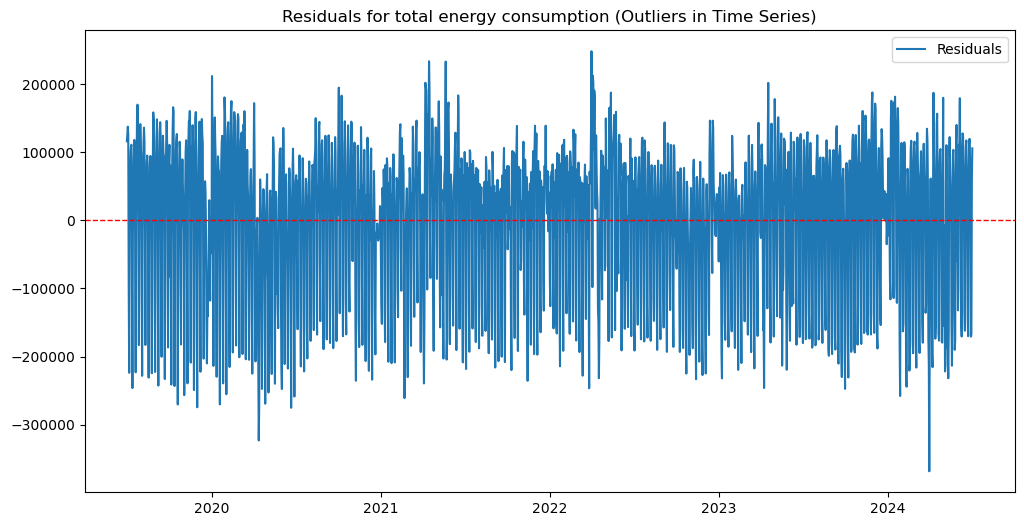

In [548]:
# Visualize decomposition
plt.figure(figsize=(12, 6))
plt.plot(residuals, label='Residuals')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.title(f"Residuals for {ts1_feature} (Outliers in Time Series)")
plt.legend()
plt.show()

In [549]:
# Identify outliers in residuals
residual_outliers = residuals[(residuals > residuals.mean() + 3 * residuals.std()) | 
                              (residuals < residuals.mean() - 3 * residuals.std())]
print(f"Outliers detected in residuals:\n{residual_outliers}")

Outliers detected in residuals:
date
2024-03-31   -368530.826351
Name: resid, dtype: float64


In [550]:
ts2_feature = 'total CO2 emissions'
decomposition = seasonal_decompose(data[ts2_feature], model='additive', period=365)
residuals = decomposition.resid

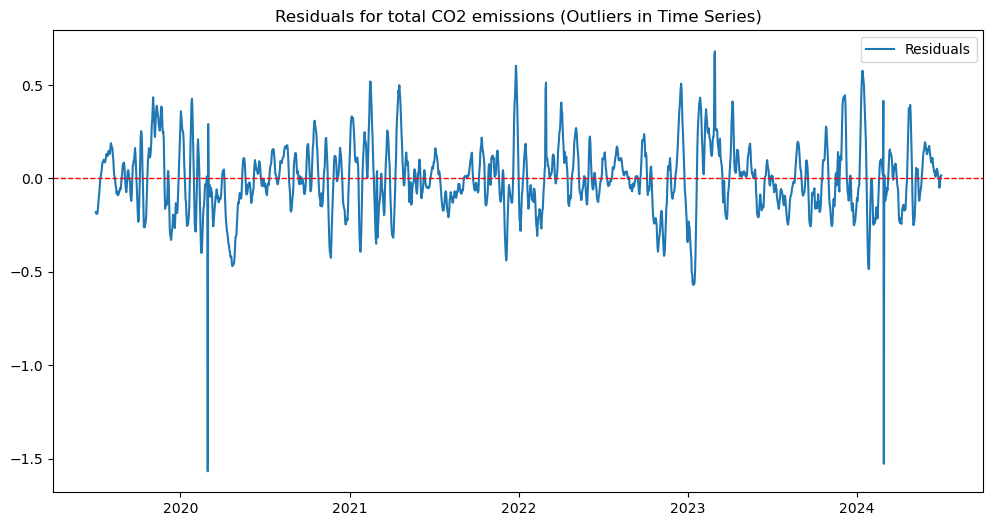

In [551]:
# Visualize decomposition
plt.figure(figsize=(12, 6))
plt.plot(residuals, label='Residuals')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.title(f"Residuals for {ts2_feature} (Outliers in Time Series)")
plt.legend()
plt.show()

In [552]:
# Identify outliers in residuals
residual_outliers = residuals[(residuals > residuals.mean() + 3 * residuals.std()) | 
                              (residuals < residuals.mean() - 3 * residuals.std())]
print(f"Outliers detected in residuals:\n{residual_outliers}")

Outliers detected in residuals:
date
2020-02-29   -1.567262
2021-12-26    0.603263
2021-12-27    0.562647
2023-01-12   -0.563111
2023-01-13   -0.569176
2023-01-14   -0.559723
2023-01-15   -0.567306
2023-02-28    0.661309
2023-03-01    0.680525
2024-01-13    0.557213
2024-01-14    0.576473
2024-02-29   -1.527323
Name: resid, dtype: float64


In [553]:
# Detect Outliers Using Z-Scores 
z_scores = data[outlier_features].apply(zscore)
outliers_z = z_scores[(z_scores > 3).any(axis=1) | (z_scores < -3).any(axis=1)]
print(f"Outliers detected using Z-Scores:\n{outliers_z}")

Outliers detected using Z-Scores:
            total energy consumption   biomass  hydropower     solar  \
date                                                                   
2019-01-01                 -1.373193  1.182867   -0.689843 -1.390795   
2019-01-02                  0.432940  1.230806   -0.866823 -1.167237   
2019-01-03                  0.915281  1.355417   -0.850609 -1.258554   
2019-01-04                  1.042775  1.441763   -0.749275 -1.396221   
2019-01-05                 -0.017945  1.328773   -0.871850 -1.425729   
...                              ...       ...         ...       ...   
2024-12-13                  0.674693 -1.166501    0.090827 -1.199485   
2024-12-28                 -0.968355 -0.943108   -0.994425 -0.831819   
2024-12-29                 -1.067488 -0.925747   -1.177406 -1.051513   
2024-12-30                 -0.259574 -1.098084   -1.150664 -1.243695   
2024-12-31                 -0.752182 -1.085966   -1.149506 -0.938258   

            other renewables 

In [554]:
# Calculate thresholds for identifying spikes
threshold = 2 * residuals.std()  # Use two times the standard deviation as a threshold

In [555]:
# Identify indices of large positive and negative residuals
outlier_indices = np.where((residuals > threshold) | (residuals < -threshold))[0]

In [556]:
# Extract the corresponding dates and values
outlier_data = data.iloc[outlier_indices]
outlier_data['Residuals'] = residuals[outlier_indices]

C:\Users\Shreya\AppData\Local\Temp\ipykernel_3216\3279856898.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outlier_data['Residuals'] = residuals[outlier_indices]


In [557]:
# Display the outlier data
print("Outliers causing spikes:")
print(outlier_data)

Outliers causing spikes:
            total energy consumption    biomass  hydropower      solar  \
date                                                                     
2019-11-02                1224070.50  115072.00    38314.00   41256.00   
2019-11-03                1128963.25  111860.00    37689.50   35287.00   
2019-11-04                1428774.75  107905.00    38857.50   47398.75   
2019-11-10                1187107.75  116773.25    37582.00   63536.50   
2019-11-11                1525379.00  116588.00    36930.75   38958.75   
...                              ...        ...         ...        ...   
2024-01-29                1397396.50  103132.75    47527.75  124965.75   
2024-02-28                1436330.25  107100.75    43192.00   99602.50   
2024-02-29                1453382.50  106861.75    40274.75  157388.00   
2024-04-23                1293951.50  103022.50    48167.50  245151.00   
2024-04-26                1255898.25  106069.00    44680.50  244980.75   

            

In [558]:
# Flag Outliers 
def identify_outliers(data, feature):
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return (data[feature] < lower_bound) | (data[feature] > upper_bound)

In [559]:
# Add an "outlier" column for each feature temporarily
outlier_flags = {}
for feature in outlier_features:
    outlier_flags[f"{feature}_outlier"] = identify_outliers(data, feature)

In [560]:
# Preserve Event-Related Data 
# Do not modify rows where events occurred
non_event_data = data[(data['COVID-19'] == 0) & (data['Russia-Ukraine War'] == 0)]

In [561]:
# Apply capping to non-event periods only
for feature in outlier_features:
    Q1 = non_event_data[feature].quantile(0.25)
    Q3 = non_event_data[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Use .loc to modify values explicitly
    non_event_data.loc[non_event_data[feature] < lower_bound, feature] = lower_bound
    non_event_data.loc[non_event_data[feature] > upper_bound, feature] = upper_bound

In [562]:
# Merge back adjusted data for non-event periods
data.update(non_event_data)

In [563]:
# Interpolation for Time-Series Features 
time_series_features = ['total energy consumption', 'total CO2 emissions']
for feature in time_series_features:
    data[feature] = data[feature].interpolate(method='linear', limit_direction='both')

In [564]:
# Drop Outlier Flags 
data = data.loc[:, ~data.columns.str.contains('_outlier')]

In [565]:
# Reset index to bring 'date' back as a column
data.reset_index(inplace=True)

In [566]:
output_file_path = 'output files/cleaned_data.csv'
data.to_csv(output_file_path, index=False)
print(f"Outliers handled while preserving events, dataset saved to {output_file_path}")

Outliers handled while preserving events, dataset saved to output files/cleaned_data.csv
